# Mental disorders, daily-life interference, and reported care

Judy Chen

Figures 01–08 use [CPES, 2001–2003](https://www.icpsr.umich.edu/web/ICPSR/studies/20240), with 10,341 respondents in the NCS-R Part 2 + NLAAS pool. Estimates use survey weights; n counts respondents, and error bars show 95% confidence intervals. Interference scores describe the worst period of the past year, from 0 (none) to 10 (very severe); eligible responses and sample sizes vary by figure. PTSD interference and care reflect narrower, event-specific questions.

## Setup

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
from scipy.stats import t

# Run this notebook from milestone2_draft; source files stay in the ignored data folder.
DATA_DIR = Path('data')
CPES_PATH = DATA_DIR / '20240-0001-Data.dta'
NSDUH_PATH = DATA_DIR / 'nsduh2024.zip'
FIGURE_DIR = Path('figures')
FIGURE_DIR.mkdir(exist_ok=True)

import altair as alt

# Display static PNGs in the notebook.
alt.renderers.enable("png")

BLUE = "#536D9A"
# ColorBrewer Dark2: the same disorder keeps the same hue in every chart.
DISORDER_COLORS = {
    "Depression": "#1b9e77",
    "Generalized anxiety": "#d95f02",
    "Panic disorder": "#7570b3",
    "Social phobia": "#e7298a",
    "Agoraphobia": "#66a61e",
    "PTSD": "#e6ab02",
}
# Fix the color mapping even when charts sort disorders differently.
DISORDER_LABELS = list(DISORDER_COLORS)
DISORDER_SCALE = alt.Scale(domain=DISORDER_LABELS, range=list(DISORDER_COLORS.values()))
NEUTRAL = "#7C8289"
# Care categories keep the same colors across the 2024 figures.
CARE_COLORS = {
    "Both": "#59A14F",
    "Professional contact only": "#4E79A7",
    "Medication only": "#E15759",
    "Neither reported": "#8C8C8C",
}
CPES_SOURCE = "CPES, 2001–2003"
NSDUH_SOURCE = "NSDUH, 2024"


# Apply one shared style, export a PNG, and return the chart for display.
def save_chart(chart, filename, title, notes):
    chart = (
        chart.properties(title=alt.TitleParams(text=title, subtitle=notes, anchor="start"))
        .configure(background="white", font="Arial", padding=12)
        .configure_axis(
            labelFontSize=11, titleFontSize=12, titlePadding=9,
            gridColor="#E5E5E5", tickCount=5, domain=False, ticks=False,
            labelColor="#333333", titleColor="#111111",
            labelLimit=230,
        )
        .configure_legend(labelFontSize=11, titleFontSize=11, padding=8)
        .configure_title(fontSize=14, subtitleFontSize=10, subtitleColor="#555555", offset=12)
        .configure_header(labelFontSize=11, labelFontWeight="normal", title=None)
        .configure_view(stroke=None)
    )
    chart.to_dict(validate=True)
    chart.save(FIGURE_DIR / filename, scale_factor=2)
    return chart


In [2]:
# Match each disorder to its CPES questionnaire variables.
# diagnosis is past-year status; ever_help is lifetime help.
# domains are home management, close relationships, and social life, in that order.
DISORDERS = {
    "Major depressive disorder": {
        "diagnosis": "V07655", "social": "V00992",
        "domains": ["V00989", "V00991", "V00992"],
        "professional_care": "V01013", "ever_help": "V00995",
    },
    "Generalized anxiety disorder": {
        "diagnosis": "V07613", "social": "V01870",
        "domains": ["V01867", "V01869", "V01870"],
        "professional_care": "V01891", "ever_help": "V01874",
    },
    "Panic disorder": {
        "diagnosis": "V07716", "social": "V01353",
        "domains": ["V01350", "V01352", "V01353"],
        "professional_care": "V01394", "ever_help": "V01357",
    },
    "Social phobia": {
        "diagnosis": "V07748", "social": "V01579",
        "domains": ["V01576", "V01578", "V01579"],
        "professional_care": "V01621", "ever_help": "V01583",
    },
    "Agoraphobia without panic disorder": {
        "diagnosis": "V07513", "social": "V01692",
        "domains": ["V01689", "V01691", "V01692"],
        "professional_care": "V01734", "ever_help": "V01697",
    },
    "PTSD": {
        "diagnosis": "V07725", "social": "V04037",
        "domains": ["V04034", "V04036", "V04037"],
        "professional_care": "V04040", "ever_help": None,
    },
}
# These variables record medication use, without identifying the condition treated.
MEDICATIONS = {
    "Antidepressants": "V02614", "Tranquilizers": "V02616",
    "Stimulants": "V02617", "Antipsychotics": "V02620",
    "Sleeping pills/sedatives": "V02807",
}
# Load only the variables needed for the figures and the survey design.
cpes_columns = {"CPESCASE", "NCNLWTLG", "SESTRAT", "SECLUSTR"}
for spec in DISORDERS.values():
    cpes_columns.update([
        spec["diagnosis"], spec["social"], spec["professional_care"], spec["ever_help"],
        *spec["domains"],
    ])
cpes_columns.discard(None)
cpes_columns.update(MEDICATIONS.values())

# Keep the common NCS-R Part 2 + NLAAS pool with its official combined weight.
cpes_raw = pd.read_stata(CPES_PATH, columns=sorted(cpes_columns), convert_categoricals=False)
# Positive NCNLWTLG weights identify respondents in this combined survey pool.
cpes = cpes_raw.loc[cpes_raw["NCNLWTLG"].gt(0)].copy()
# Check the file size, unique respondent IDs, and selected pool size.
assert len(cpes_raw) == 20_013 and cpes_raw["CPESCASE"].is_unique
assert len(cpes) == 10_341

# NSDUH fields cover depression, impairment, care, insurance, and sampling design.
nsduh_columns = [
    "IRAMDEYR", "IRAMDEIMP", "ATXMDEYR", "ARXMDEYR",
    "ANALWT2_C", "VESTR_C", "VEREP", "IRINSUR4",
]
# Read directly from the ZIP; a period in the data marks a missing response.
with zipfile.ZipFile(NSDUH_PATH) as archive:
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_raw = pd.read_csv(stream, sep="\t", usecols=nsduh_columns, na_values=["."])
assert len(nsduh_raw) == 58_633
# Adult depression status uses 0=no and 1=yes; then keep past-year cases.
nsduh_adults = nsduh_raw.loc[nsduh_raw["IRAMDEYR"].isin([0, 1])].copy()
nsduh_mde = nsduh_adults.loc[nsduh_adults["IRAMDEYR"].eq(1)].copy()
# Require known answers to both care items; unknown answers are not "no."
care_known = nsduh_mde["ATXMDEYR"].isin([0, 1]) & nsduh_mde["ARXMDEYR"].isin([0, 1])
nsduh_care = nsduh_mde.loc[care_known].copy()
# Check "both" first so the four care categories do not overlap.
nsduh_care["care_group"] = np.select([
    nsduh_care["ATXMDEYR"].eq(1) & nsduh_care["ARXMDEYR"].eq(1),
    nsduh_care["ATXMDEYR"].eq(1),
    nsduh_care["ARXMDEYR"].eq(1),
], ["Both", "Professional contact only", "Medication only"], default="Neither reported")
nsduh_care["reported_either"] = nsduh_care["ATXMDEYR"].eq(1) | nsduh_care["ARXMDEYR"].eq(1)
assert len(nsduh_adults) == 47_299 and len(nsduh_mde) == 5_205
assert len(nsduh_care) == 5_008 and (~care_known).sum() == 197


care_values = {}
care_coverage = []
for name, spec in DISORDERS.items():
    observed = cpes[spec["professional_care"]]
    # CPES uses 1=yes and 5=no; recode to 1/0 and leave unknown answers missing.
    care = observed.map({1: 1.0, 5: 0.0})
    inferred_no = pd.Series(False, index=cpes.index)
    if spec["ever_help"] is not None:
        never_help = cpes[spec["ever_help"]].eq(5)
        assert not (never_help & observed.eq(1)).any()
        # An explicit lifetime "no" rules out past-year help for this disorder.
        inferred_no = observed.isna() & never_help
        care = care.mask(inferred_no, 0.0)
    # PTSD's lifetime item concerns a selected event: do not infer from it.
    care_values[name] = care
    cases = cpes[spec["diagnosis"]].eq(1)
    # Track known responses because care denominators differ across disorders.
    care_coverage.append({"name": name, "cases": int(cases.sum()),
                          "known": int((cases & care.notna()).sum()),
                          "inferred_no": int((cases & inferred_no).sum())})
assert [r["known"] for r in care_coverage] == [916, 496, 353, 849, 220, 257]


In [3]:
def survey_mean(frame, values, domain=None, *, weight, strata, cluster):
    """Weighted domain mean with a Taylor-linearized, survey-design 95% CI.

    Keep the full survey pool: observations outside the domain contribute zero
    to the linearized residual, but their strata and clusters remain in the design.
    """
    # domain selects a subgroup; only its non-missing answers enter the mean.
    y = pd.Series(values, index=frame.index, dtype=float)
    active = y.notna()
    if domain is not None:
        active &= pd.Series(domain, index=frame.index).fillna(False).astype(bool)
    w = frame[weight].astype(float)
    if not np.isfinite(w).all() or not w.gt(0).all():
        raise ValueError("Use a full analysis pool with finite, positive survey weights.")
    if frame[[strata, cluster]].isna().any().any():
        raise ValueError("Missing survey design identifiers need investigation.")
    denominator = w.loc[active].sum()
    if denominator <= 0:
        raise ValueError("No valid weighted observations in the requested domain.")
    # For 0/1 answers, a weighted mean is the estimated population proportion.
    estimate = float(np.average(y.loc[active], weights=w.loc[active]))
    # Other respondents contribute zero here but stay in the sampling design.
    residual = (y - estimate).where(active, 0.0)
    # Estimate variation between clusters within each sampling stratum.
    design = frame[[strata, cluster]].copy()
    design["linearized"] = w * residual / denominator
    psu_totals = design.groupby([strata, cluster], observed=True)["linearized"].sum()
    components = psu_totals.groupby(level=0).agg(["count", "sum"])
    if components["count"].lt(2).any():
        raise ValueError("A single-PSU stratum needs a documented variance treatment.")
    centered = psu_totals - psu_totals.groupby(level=0).transform("mean")
    square_sums = centered.pow(2).groupby(level=0).sum()
    m = components["count"]
    # Combine the stratum contributions to calculate the standard error.
    variance = float((m / (m - 1) * square_sums).sum())
    se = float(np.sqrt(max(variance, 0)))
    # The survey design determines the t multiplier for a 95% interval.
    degrees_freedom = int((m - 1).sum())
    critical = float(t.ppf(0.975, degrees_freedom))
    return {
        "estimate": estimate, "se": se,
        "lower": estimate - critical * se, "upper": estimate + critical * se,
        "n": int(active.sum()), "design_df": degrees_freedom,
    }

# Supply the weight, stratum, and sampling-cluster columns for each survey.
CPES_DESIGN = {"weight": "NCNLWTLG", "strata": "SESTRAT", "cluster": "SECLUSTR"}
NSDUH_DESIGN = {"weight": "ANALWT2_C", "strata": "VESTR_C", "cluster": "VEREP"}


## Figure 01 · Past-year prevalence

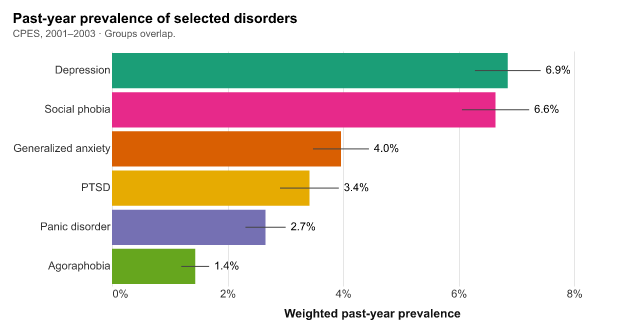

In [4]:
prevalence = pd.DataFrame([
    {"name": label, **survey_mean(cpes, cpes[spec["diagnosis"]].map({1: 1., 5: 0.}), **CPES_DESIGN)}
    for label, spec in zip(DISORDER_LABELS, DISORDERS.values())
]).sort_values("estimate")


def prevalence_chart(df):
    disorder_order = df.sort_values("estimate", ascending=False)["name"].tolist()
    base = alt.Chart(df).encode(
        y=alt.Y("name:N", sort=disorder_order, title=None),
    )
    bars = base.mark_bar().encode(
        x=alt.X("estimate:Q", title="Weighted past-year prevalence", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .09], nice=False)),
        color=alt.Color("name:N", legend=None,
                        scale=DISORDER_SCALE),
    )
    intervals = base.mark_rule(color="#444444").encode(x="lower:Q", x2="upper:Q")
    labels = base.mark_text(align="left", dx=5).encode(
        x="upper:Q", text=alt.Text("estimate:Q", format=".1%"),
    )
    return (bars + intervals + labels).properties(width=520, height=235)


save_chart(
    prevalence_chart(prevalence), "01_prevalence.png", "Past-year prevalence of selected disorders",
    [CPES_SOURCE + " · Groups overlap."],
)


## Figure 02 · Which disorders occurred together?

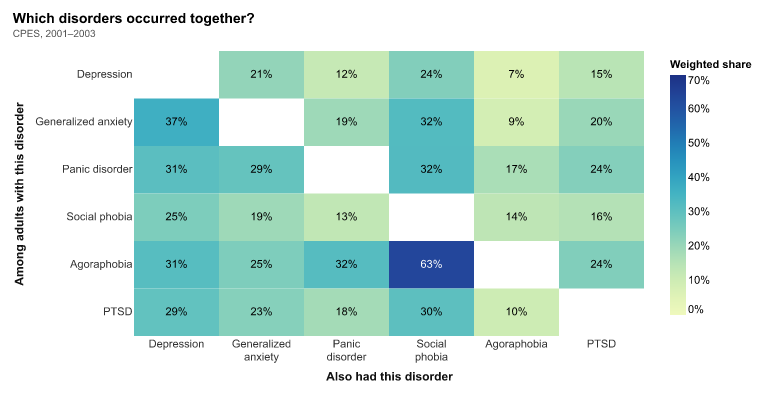

In [5]:
diagnosis_columns = [spec["diagnosis"] for spec in DISORDERS.values()]
assert cpes[diagnosis_columns].isin([1, 5]).all().all()
flags = cpes[diagnosis_columns].eq(1).to_numpy()
weights = cpes["NCNLWTLG"].to_numpy()
cooccurrence = np.full((6, 6), np.nan)
for row in range(6):
    for col in range(6):
        if row != col:
            cooccurrence[row, col] = np.average(flags[flags[:, row], col], weights=weights[flags[:, row]])*100


cooccurrence_df = pd.DataFrame([
    {"disorder": DISORDER_LABELS[row], "also_had": DISORDER_LABELS[col],
     "share": cooccurrence[row, col] / 100}
    for row in range(6) for col in range(6) if row != col
])


def cooccurrence_chart(df):
    base = alt.Chart(df).encode(
        x=alt.X("also_had:N", title="Also had this disorder", sort=DISORDER_LABELS,
                axis=alt.Axis(labelAngle=0, labelExpr="split(datum.label, ' ')", labelLineHeight=13)),
        y=alt.Y("disorder:N", title="Among adults with this disorder", sort=DISORDER_LABELS),
    )
    cells = base.mark_rect().encode(
        color=alt.Color("share:Q", title="Weighted share", scale=alt.Scale(scheme="yellowgreenblue", domain=[0, .7], nice=False),
                        legend=alt.Legend(format="%", values=[0, .1, .2, .3, .4, .5, .6, .7], labelOverlap=False, gradientLength=240)),
    )
    # Switch text color only where the sequential palette becomes dark enough.
    labels = base.mark_text().encode(
        text=alt.Text("share:Q", format=".0%"),
        color=alt.condition("datum.share > .5", alt.value("white"), alt.value("black")),
    )
    return (cells + labels).properties(width=510, height=285)


save_chart(
    cooccurrence_chart(cooccurrence_df), "02_cooccurrence_heatmap.png", "Which disorders occurred together?",
    [CPES_SOURCE],
)


## Figure 03 · Which disorder combinations were most common?

The ten largest exact combinations are shown among 754 respondents with at least two selected disorders; the remaining combinations account for 36.5%. Colored dots indicate disorders present and pale gray dots indicate disorders absent, with faint row bands repeating the disorder colors.

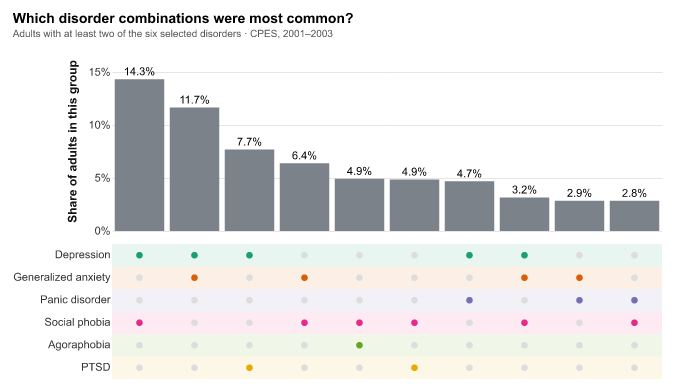

In [6]:
# Group the six yes/no columns directly: each group is one exact combination.
diagnosis_flags = cpes[diagnosis_columns].eq(1).set_axis(DISORDER_LABELS, axis=1)
multi = diagnosis_flags.sum(axis=1).ge(2)
combination_weights = (
    diagnosis_flags.loc[multi].assign(weight=cpes.loc[multi, "NCNLWTLG"])
    .groupby(DISORDER_LABELS)["weight"].sum()
    .sort_values(ascending=False)
)
top_combinations = combination_weights.head(10).reset_index()
top_combinations["combination"] = [str(i + 1) for i in range(len(top_combinations))]
top_combinations["share"] = top_combinations["weight"] / combination_weights.sum()
omitted_share = 100 * (1 - top_combinations["share"].sum())

combinations = top_combinations["combination"].tolist()
combination_df = top_combinations[["combination", "share"]]
membership_df = top_combinations.melt(
    id_vars="combination", value_vars=DISORDER_LABELS,
    var_name="disorder", value_name="included",
)

def combinations_chart(bars_df, dots_df):
    bars = alt.Chart(bars_df).mark_bar(color=NEUTRAL).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("share:Q", title="Share of adults in this group", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .17])),
    )
    labels = bars.mark_text(dy=-7).encode(text=alt.Text("share:Q", format=".1%"))
    # Faint bands repeat each disorder's color to help readers follow the rows.
    row_bands = alt.Chart(pd.DataFrame({"disorder": DISORDER_LABELS})).mark_rect(opacity=.10).encode(
        x=alt.value(0), x2=alt.value(550),
        y=alt.Y("disorder:N", sort=DISORDER_LABELS, scale=alt.Scale(domain=DISORDER_LABELS),
                title=None, axis=alt.Axis(ticks=False, domain=False)),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    dots = alt.Chart(dots_df).mark_point(filled=True, size=45, opacity=1).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("disorder:N", sort=DISORDER_LABELS, scale=alt.Scale(domain=DISORDER_LABELS),
                title=None, axis=alt.Axis(ticks=False, domain=False)),
        color=alt.condition("datum.included",
                            alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
                            alt.value("#DDDDDD")),
    )
    return alt.vconcat(
        (bars + labels).properties(width=550, height=180),
        (row_bands + dots).properties(width=550, height=135), spacing=8,
    ).resolve_scale(x="shared")


save_chart(
    combinations_chart(combination_df, membership_df), "03_upset.png", "Which disorder combinations were most common?",
    ["Adults with at least two of the six selected disorders · " + CPES_SOURCE],
)


## Figure 04 · Social-life interference distributions

Dots show the observed percentages at each whole-number score; curves guide the eye between them. Each disorder has a shaded row with its own percentage guides, using the same 0–25% scale.

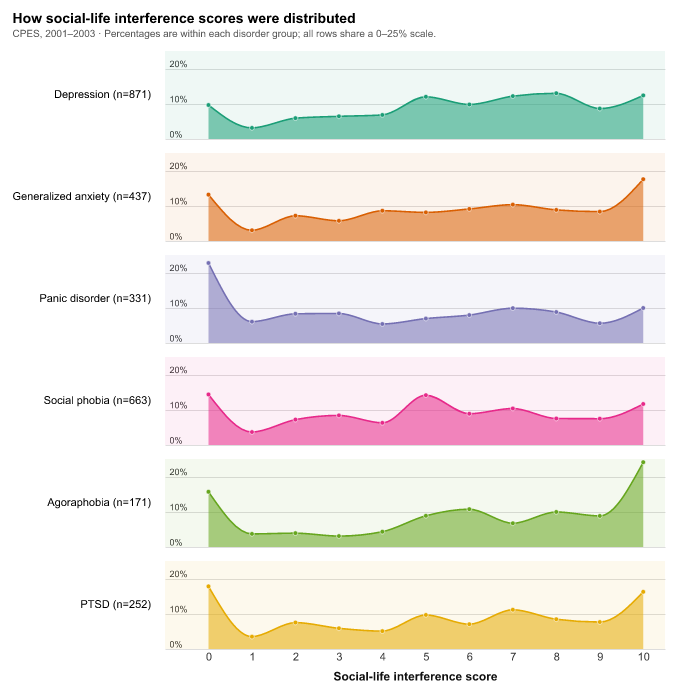

In [7]:
score_distributions, score_counts = [], []
for spec in DISORDERS.values():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["social"]].between(0, 10)
    counts = cpes.loc[valid].groupby(spec["social"])["NCNLWTLG"].sum().reindex(range(11), fill_value=0)
    score_distributions.append(counts / counts.sum()*100)
    score_counts.append(int(valid.sum()))


panel_order = [f"{label} (n={n:,})" for label, n in zip(DISORDER_LABELS, score_counts)]
distribution_df = pd.DataFrame([
    {"panel": panel, "disorder": disorder, "score": score,
     "share": float(distribution.loc[score]) / 100}
    for disorder, panel, distribution in zip(DISORDER_LABELS, panel_order, score_distributions) for score in range(11)
])


def interference_distributions(df):
    # Shade each row; the left margin gives its percentage labels their own space.
    row_background = alt.Chart(df).transform_aggregate(
        groupby=["panel", "disorder"],
    ).mark_rect(opacity=.07).encode(
        x=alt.value(0), x2=alt.value(500), y=alt.value(0), y2=alt.value(88),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    base = alt.Chart(df).encode(
        x=alt.X("score:Q", title="Social-life interference score",
                scale=alt.Scale(domain=[-1, 10.5], nice=False),
                axis=alt.Axis(values=list(range(11)), tickCount=11, grid=False,
                              labelAngle=0, labelOverlap=False)),
        y=alt.Y("share:Q", title=None, stack=None,
                scale=alt.Scale(domain=[0, .25], nice=False),
                axis=alt.Axis(values=[0, .1, .2], format=".0%", tickCount=3,
                              labelFontSize=9, labelPadding=-4, labelAlign="left",
                              labelBaseline="bottom", labelOverlap=False,
                              grid=True, gridColor="#DDDDDD", gridOpacity=1)),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    # Monotone curves connect the observations; dots retain the actual score values.
    fill = base.mark_area(interpolate="monotone", opacity=.55)
    outline = base.mark_line(interpolate="monotone", strokeWidth=1.6)
    points = base.mark_point(filled=True, size=22, opacity=1,
                             stroke="white", strokeWidth=.6)
    profiles = (row_background + fill + outline + points).properties(width=500, height=88)
    return profiles.facet(
        row=alt.Row("panel:N", sort=panel_order, title=None,
                    header=alt.Header(labelAngle=0, labelAlign="left", labelPadding=14,
                                      labelFontSize=11)),
        spacing=14,
    ).resolve_scale(x="shared", y="shared")


save_chart(
    interference_distributions(distribution_df), "04_social_interference_distributions.png", "How social-life interference scores were distributed",
    [CPES_SOURCE + " · Percentages are within each disorder group; all rows share a 0–25% scale."],
)


## Figure 05 · Daily-life domains

Shapes identify the three domains, and each disorder keeps its assigned color. Connecting lines span the lowest and highest domain averages within a disorder.

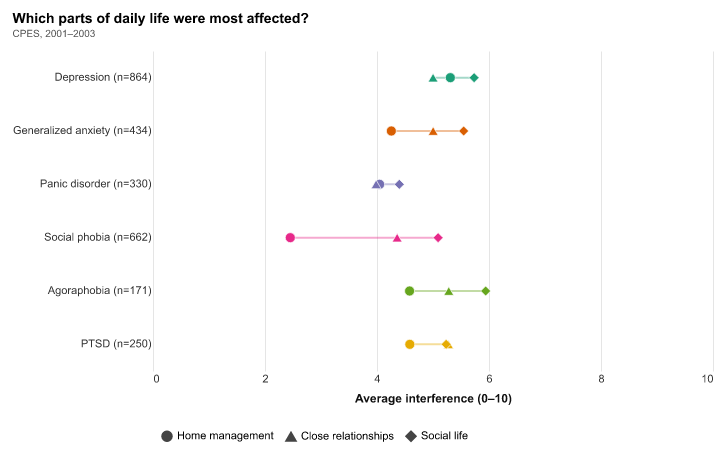

In [8]:
domain_means, complete_counts = [], []
for spec in DISORDERS.values():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["domains"]].apply(lambda s: s.between(0,10)).all(axis=1)
    domain_means.append([np.average(cpes.loc[valid, v], weights=cpes.loc[valid,"NCNLWTLG"]) for v in spec["domains"]])
    complete_counts.append(int(valid.sum()))
assert complete_counts == [864, 434, 330, 662, 171, 250]


domains = ["Home management", "Close relationships", "Social life"]
domain_labels = [f"{label} (n={n:,})" for label, n in zip(DISORDER_LABELS, complete_counts)]
domain_df = pd.DataFrame([
    {"disorder": domain_labels[row], "name": DISORDER_LABELS[row],
     "domain": domain, "mean_score": domain_means[row][col]}
    for row in range(6) for col, domain in enumerate(domains)
])



def domain_interference_chart(df):
    # Each line spans the lowest and highest of the three domain averages.
    spans = alt.Chart(df).transform_aggregate(
        lowest="min(mean_score)", highest="max(mean_score)",
        groupby=["disorder", "name"],
    ).mark_rule(strokeWidth=2, opacity=.4).encode(
        y=alt.Y("disorder:N", sort=domain_labels, title=None),
        x=alt.X("lowest:Q", title="Average interference (0–10)",
                scale=alt.Scale(domain=[0, 10], nice=False),
                axis=alt.Axis(values=[0, 2, 4, 6, 8, 10], tickCount=6, labelOverlap=False)),
        x2="highest:Q",
        color=alt.Color("name:N", scale=DISORDER_SCALE, legend=None),
    )
    points = alt.Chart(df).mark_point(
        filled=True, size=100, opacity=1, stroke="white", strokeWidth=.7,
    ).encode(
        y=alt.Y("disorder:N", sort=domain_labels, title=None),
        x=alt.X("mean_score:Q", title="Average interference (0–10)",
                scale=alt.Scale(domain=[0, 10], nice=False),
                axis=alt.Axis(values=[0, 2, 4, 6, 8, 10], tickCount=6, labelOverlap=False)),
        color=alt.Color("name:N", scale=DISORDER_SCALE, legend=None),
        shape=alt.Shape("domain:N", title=None,
                        scale=alt.Scale(domain=domains, range=["circle", "triangle-up", "diamond"]),
                        legend=alt.Legend(orient="bottom", columns=3, labelLimit=180,
                                          symbolStrokeColor="#444444", symbolFillColor="#444444",
                                          symbolStrokeWidth=1.5, symbolOpacity=1)),
    )
    return (spans + points).properties(width=560, height=320)


save_chart(
    domain_interference_chart(domain_df), "05_daily_life_domains.png", "Which parts of daily life were most affected?",
    [CPES_SOURCE],
)


## Figure 06 · Disorder-specific professional care

Labels show respondents with known care status / all past-year cases.

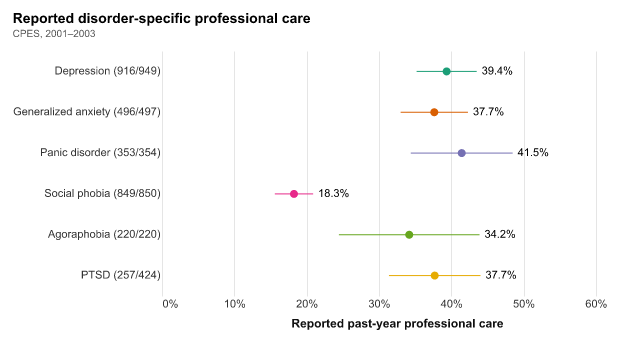

In [9]:
care_rows = []
for label, (name, spec), coverage in zip(DISORDER_LABELS, DISORDERS.items(), care_coverage):
    cases = cpes[spec["diagnosis"]].eq(1)
    result = survey_mean(cpes, care_values[name], cases, **CPES_DESIGN)
    care_rows.append({"label": label, "case_n": coverage["cases"], **result})
professional_care = pd.DataFrame(care_rows)


care_plot = professional_care.assign(
    group=[f"{r.label} ({r.n}/{r.case_n})" for r in professional_care.itertuples()]
)


def professional_care_chart(df):
    base = alt.Chart(df).encode(
        y=alt.Y("group:N", sort=df["group"].tolist(), title=None),
        color=alt.Color("label:N", scale=DISORDER_SCALE, legend=None),
    )
    intervals = base.mark_rule().encode(
        x=alt.X("lower:Q", title="Reported past-year professional care", axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .65])), x2="upper:Q",
    )
    points = base.mark_point(filled=True, opacity=1, size=65).encode(x="estimate:Q")
    labels = base.mark_text(align="left", dx=5).encode(x="upper:Q", text=alt.Text("estimate:Q", format=".1%"), color=alt.value("black"))
    return (intervals + points + labels).properties(width=470, height=245)


save_chart(
    professional_care_chart(care_plot), "06_professional_care.png", "Reported disorder-specific professional care",
    [CPES_SOURCE],
)


## Figure 07 · Medication classes

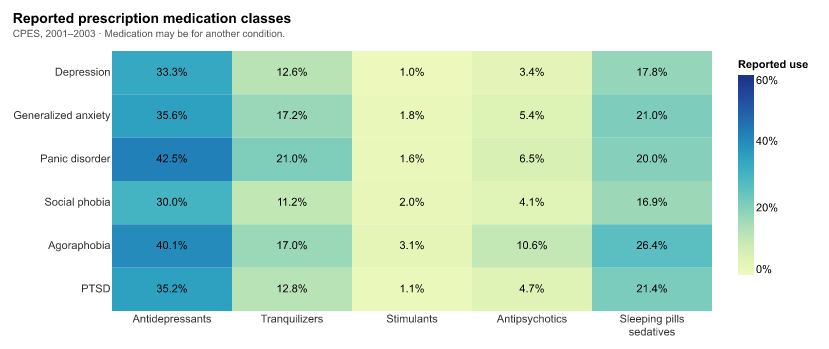

In [10]:
medication_rows = []
for disorder_label, (name, spec) in zip(DISORDER_LABELS, DISORDERS.items()):
    cases = cpes[spec["diagnosis"]].eq(1)
    for medication, variable in MEDICATIONS.items():
        values = cpes[variable].map({1: 1., 5: 0.})
        result = survey_mean(cpes, values, cases, **CPES_DESIGN)
        medication_rows.append({
            "disorder": disorder_label, "medication": medication.replace("/", " / "),
            "share": result["estimate"], "label": f"{result['estimate']:.1%}",
            **result,
        })
medication_df = pd.DataFrame(medication_rows)
medication_labels = [name.replace("/", " / ") for name in MEDICATIONS]


def medication_chart(df):
    base = alt.Chart(df).encode(
        x=alt.X("medication:N", sort=medication_labels, title=None,
                axis=alt.Axis(labelAngle=0, labelExpr="split(datum.label, ' / ')", labelLineHeight=13)),
        y=alt.Y("disorder:N", sort=DISORDER_LABELS, title=None),
    )
    cells = base.mark_rect().encode(
        color=alt.Color("share:Q", title="Reported use", scale=alt.Scale(scheme="yellowgreenblue", domain=[0, .6]),
                        legend=alt.Legend(format="%")),
    )
    labels = base.mark_text().encode(
        text="label:N",
        color=alt.condition("datum.share > .432", alt.value("white"), alt.value("black")),
    )
    return (cells + labels).properties(width=600, height=260)


save_chart(
    medication_chart(medication_df), "07_medication_classes.png", "Reported prescription medication classes",
    [CPES_SOURCE + " · Medication may be for another condition."],
)


## Figure 08 · Interference and reported care

Both measures use the same respondents within each disorder and score band; respondent counts appear beneath the score labels. Professional care refers to that disorder; antidepressant use may be for another condition, and the score bands are not clinical severity categories.

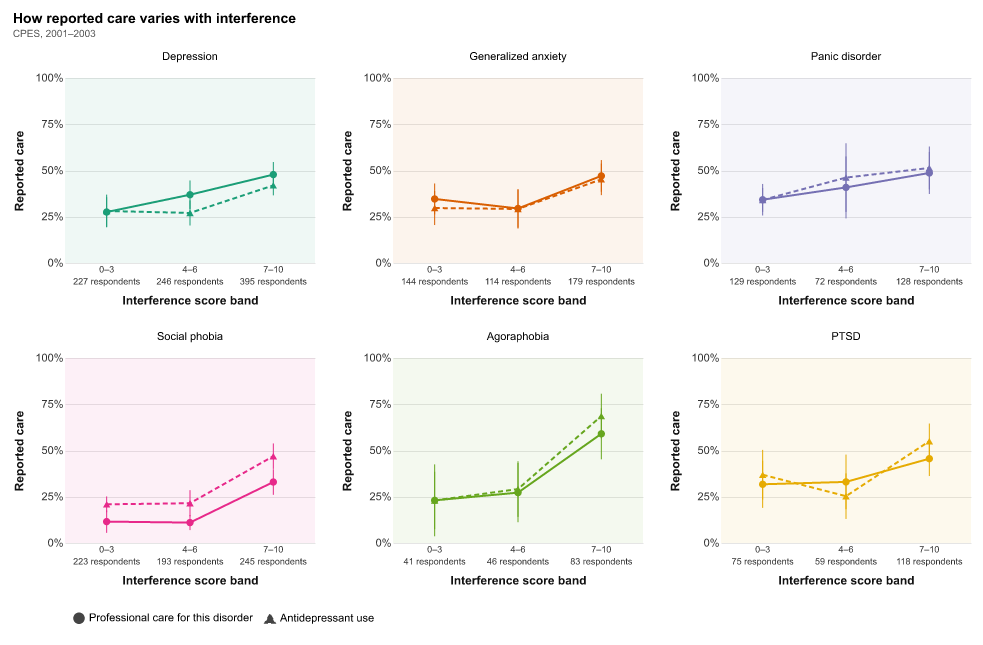

In [11]:
bands = [(0, 3), (4, 6), (7, 10)]
care_measures = ["Professional care for this disorder", "Antidepressant use"]
interference_care_rows = []
antidepressants = cpes["V02614"].map({1: 1., 5: 0.})

for label, (name, spec) in zip(DISORDER_LABELS, DISORDERS.items()):
    score = cpes[spec["social"]]
    # Both care measures use the same respondents within each disorder and band.
    eligible = (cpes[spec["diagnosis"]].eq(1) & score.between(0, 10)
                & care_values[name].notna() & antidepressants.notna())
    measures = {care_measures[0]: care_values[name], care_measures[1]: antidepressants}
    for low, high in bands:
        group = eligible & score.between(low, high)
        band = f"{low}–{high}"
        for measure, values in measures.items():
            result = survey_mean(cpes, values, group, **CPES_DESIGN)
            interference_care_rows.append({"disorder": label, "band": band,
                                           "measure": measure, **result})

interference_care = pd.DataFrame(interference_care_rows)
# Put each group's respondent count on the second line of its score label.
interference_care["band_label"] = (
    interference_care["band"] + "|" + interference_care["n"].astype(str) + " respondents"
)
band_label_order = interference_care.sort_values("band")["band_label"].drop_duplicates().tolist()


def interference_care_chart(df):
    measure_legend = alt.Legend(
        title=None, orient="bottom", columns=2, labelLimit=270,
        symbolOpacity=1, symbolFillColor="#444444", symbolStrokeColor="#444444",
    )
    background = alt.Chart(df).transform_aggregate(groupby=["disorder"]).mark_rect(opacity=.07).encode(
        x=alt.value(0), x2=alt.value(250), y=alt.value(0), y2=alt.value(185),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    base = alt.Chart(df).encode(
        x=alt.X("band_label:O", sort=band_label_order, title="Interference score band",
                axis=alt.Axis(labelAngle=0, labelExpr="split(datum.label, '|')",
                              labelFontSize=9, labelLineHeight=12, labelOverlap=False)),
        y=alt.Y("estimate:Q", title="Reported care", scale=alt.Scale(domain=[0, 1]),
                axis=alt.Axis(format="%", values=[0, .25, .5, .75, 1],
                              labelOverlap=False)),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    # Lines only connect the three observed bands; they are not fitted trends.
    lines = base.mark_line(strokeWidth=2).encode(
        strokeDash=alt.StrokeDash("measure:N", title=None,
                                  scale=alt.Scale(domain=care_measures, range=[[1, 0], [5, 3]]),
                                  legend=measure_legend),
    )
    intervals = base.mark_rule(strokeWidth=1).encode(y="lower:Q", y2="upper:Q")
    points = base.mark_point(filled=True, size=55, opacity=1).encode(
        shape=alt.Shape("measure:N", title=None,
                        scale=alt.Scale(domain=care_measures, range=["circle", "triangle-up"]),
                        legend=measure_legend),
    )
    return (background + lines + intervals + points).properties(width=250, height=185).facet(
        facet=alt.Facet("disorder:N", sort=DISORDER_LABELS, title=None), columns=3, spacing=25,
    ).resolve_scale(x="independent", y="shared").resolve_axis(y="independent")


save_chart(
    interference_care_chart(interference_care), "08_interference_and_care.png", "How reported care varies with interference",
    [CPES_SOURCE],
)


## Figure 09 · Depression-related care in 2024

Figures 09–11 use [NSDUH 2024](https://www.samhsa.gov/data/data-we-collect/nsduh-national-survey-drug-use-and-health/datafiles/2024), analyzed separately from CPES. They include 5,008 adults with past-year depression and known responses about professional contact and prescription medication for depressive feelings. There are 197 excluded cases with unknown care status, including 145 with severe impairment; the two surveys do not form a direct trend.

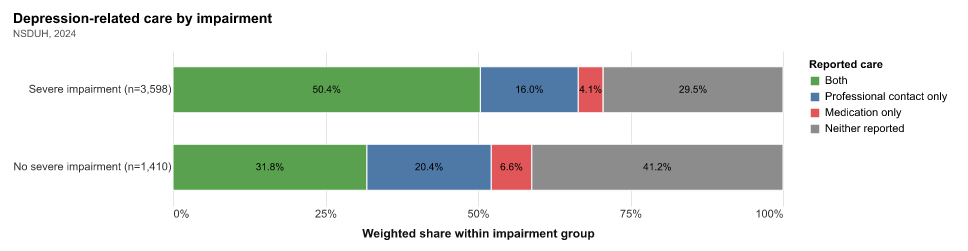

In [12]:
statuses = list(CARE_COLORS)

care_stack_rows = []
for group_code, group_label in [(1, "Severe impairment (n=3,598)"), (0, "No severe impairment (n=1,410)")]:
    group = nsduh_care.loc[nsduh_care["IRAMDEIMP"].eq(group_code)]
    totals = group.groupby("care_group")["ANALWT2_C"].sum().reindex(statuses, fill_value=0)
    cumulative = 0
    for order, status in enumerate(statuses):
        share = float(totals[status] / totals.sum())
        care_stack_rows.append({"impairment": group_label, "care": status, "weight": float(totals[status]),
                                "share": share, "middle": cumulative + share / 2, "order": order})
        cumulative += share
care_stack_df = pd.DataFrame(care_stack_rows)
assert np.allclose(care_stack_df.groupby("impairment")["share"].sum(), 1)


def care_combinations_chart(df):
    base = alt.Chart(df).encode(
        y=alt.Y("impairment:N", sort=df["impairment"].drop_duplicates().tolist(), title=None),
    )
    bars = base.mark_bar(size=46, stroke="white", strokeWidth=1).encode(
        x=alt.X("sum(weight):Q", title="Weighted share within impairment group",
                scale=alt.Scale(domain=[0, 1], nice=False))
          .stack("normalize").axis(format="%", values=[0, .25, .5, .75, 1]),
        color=alt.Color("care:N", title="Reported care", scale=alt.Scale(domain=statuses, range=list(CARE_COLORS.values()))),
        order=alt.Order("order:Q", sort="ascending"),
    )
    labels = base.mark_text(fontSize=10, color="black").encode(
        x="middle:Q", text=alt.Text("share:Q", format=".1%"),
    )
    return (bars + labels).properties(width=610, height=155)


save_chart(
    care_combinations_chart(care_stack_df), "09_depression_care_combinations.png", "Depression-related care by impairment",
    [NSDUH_SOURCE],
)


## Figure 10 · Insurance and reported care

This comparison includes adults with depression and severe role impairment. It describes an association rather than an effect of insurance.

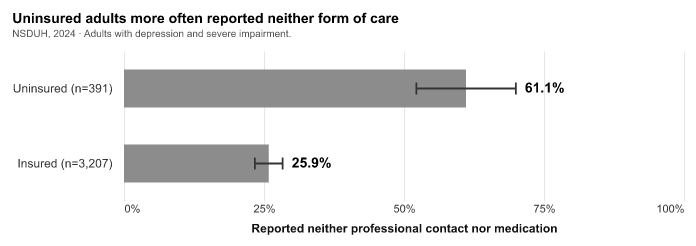

In [13]:
known = nsduh_raw["ATXMDEYR"].isin([0,1]) & nsduh_raw["ARXMDEYR"].isin([0,1])
neither = (nsduh_raw["ATXMDEYR"].eq(0) & nsduh_raw["ARXMDEYR"].eq(0)).astype(float).where(known)
severe = nsduh_raw["IRAMDEYR"].eq(1) & nsduh_raw["IRAMDEIMP"].eq(1)
insurance_rows=[]
for insurance_code,label in [(1,"Insured"),(2,"Uninsured")]:
    result=survey_mean(nsduh_raw,neither,severe & nsduh_raw["IRINSUR4"].eq(insurance_code),**NSDUH_DESIGN)
    insurance_rows.append({"label":label,**result})
insurance_rates=pd.DataFrame(insurance_rows)
assert insurance_rates["n"].tolist()==[3207,391]


insurance_plot = insurance_rates.assign(group=[f"{r.label} (n={r.n:,})" for r in insurance_rates.itertuples()])


def insurance_care_chart(df):
    order = df.sort_values("estimate", ascending=False)["group"].tolist()
    base = alt.Chart(df).encode(
        y=alt.Y("group:N", title=None, sort=order,
                axis=alt.Axis(labelFontSize=12, labelPadding=12)),
        x=alt.X("estimate:Q", title="Reported neither professional contact nor medication",
                scale=alt.Scale(domain=[0, 1], nice=False),
                axis=alt.Axis(format="%", values=[0, .25, .5, .75, 1],
                              labelOverlap=False)),
    )
    bars = base.mark_bar(size=38, color=CARE_COLORS["Neither reported"])
    # Dark capped lines keep the 95% intervals visible over the bars.
    intervals = base.mark_rule(color="#333333", strokeWidth=1.8).encode(
        x="lower:Q", x2="upper:Q",
    )
    lower_caps = base.mark_tick(orient="vertical", color="#333333", opacity=1,
                                size=12, thickness=1.8).encode(x="lower:Q")
    upper_caps = base.mark_tick(orient="vertical", color="#333333", opacity=1,
                                size=12, thickness=1.8).encode(x="upper:Q")
    labels = base.mark_text(align="left", dx=9, fontSize=14, fontWeight="bold").encode(
        x="upper:Q", text=alt.Text("estimate:Q", format=".1%"),
    )
    return (bars + intervals + lower_caps + upper_caps + labels).properties(width=560, height=150)


save_chart(
    insurance_care_chart(insurance_plot), "10_insurance_care_comparison.png", "Uninsured adults more often reported neither form of care",
    [NSDUH_SOURCE + " · Adults with depression and severe impairment."],
)


## Figure 11 · Optional experiment: impairment, insurance, and care

Bar colors distinguish the three columns; blue and gray ribbons show care categories. Ribbon widths show shares of the full analysis group, not a treatment sequence or rates within each subgroup.

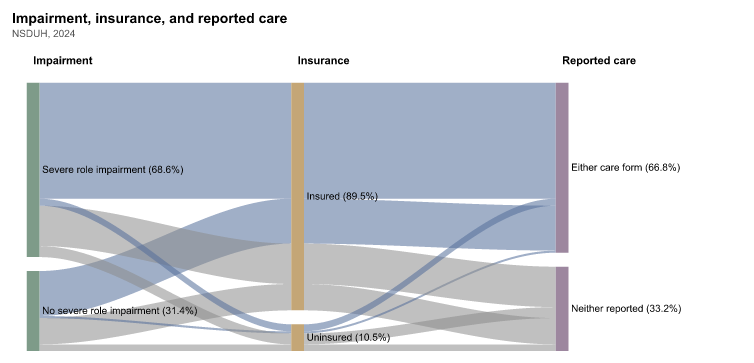

In [14]:
assert nsduh_care["IRAMDEIMP"].isin([0,1]).all() and nsduh_care["IRINSUR4"].isin([1,2]).all()
paths=nsduh_care.groupby(["IRAMDEIMP","IRINSUR4","reported_either"])["ANALWT2_C"].sum()
paths=paths/paths.sum()
assert np.isclose(paths.sum(),1) and len(paths)==8
stage_names = ["Impairment", "Insurance", "Reported care"]
stage_colors = ["#7E9B89", "#C4A676", "#9D879F"]
stage_values=[[1,0],[1,2],[True,False]]
stage_labels=[["Severe role\nimpairment","No severe role\nimpairment"],["Insured","Uninsured"],["Either care form","Neither reported"]]
nodes,slots={},{}
gap=.055
for stage,values in enumerate(stage_values):
    cursor=1+gap
    for value in values:
        members=[p for p in paths.index if p[stage]==value]
        total=sum(paths[p] for p in members)
        top,bottom=cursor,cursor-total
        nodes[stage,value]=(bottom,top,total)
        offset=top
        for p in sorted(members,key=lambda p:(not p[2], -p[0], p[1])):
            slots[stage,p]=(offset-paths[p],offset)
            offset-=paths[p]
        assert np.isclose(offset,bottom)
        cursor=bottom-gap


ribbon_rows, node_rows = [], []
for path, share in paths.items():
    for stage in [0, 1]:
        low0, high0 = slots[stage, path]
        low1, high1 = slots[stage+1, path]
        for fraction in np.linspace(0, 1, 41):
            smooth = fraction*fraction*(3-2*fraction)
            low = low0 + (low1-low0)*smooth
            high = high0 + (high1-high0)*smooth
            assert np.isclose(high-low, share)
            ribbon_rows.append({"ribbon": str(path)+str(stage), "x": stage*.5+.012+fraction*.476,
                                "low": low, "high": high, "care": "Either care form" if path[2] else "Neither reported"})
for stage, values in enumerate(stage_values):
    for value, label in zip(values, stage_labels[stage]):
        bottom, top, share = nodes[stage, value]
        node_rows.append({"stage": stage_names[stage], "x": stage*.5, "left": stage*.5-.012, "right": stage*.5+.012,
                          "low": bottom, "high": top, "middle": (bottom+top)/2,
                          "label": label.replace("\n", " ")+f" ({share:.1%})"})
ribbon_df = pd.DataFrame(ribbon_rows)
node_df = pd.DataFrame(node_rows)
stage_df = pd.DataFrame({"x": [0, .5, 1], "label": stage_names})


def impairment_insurance_care_chart(ribbons, nodes, stages):
    xs = alt.Scale(domain=[-.04, 1.34], nice=False)
    ys = alt.Scale(domain=[0, 1.18], nice=False)
    flow = alt.Chart(ribbons).mark_area(orient="vertical", opacity=.55).encode(
        x=alt.X("x:Q", scale=xs, axis=None),
        y=alt.Y("low:Q", scale=ys, axis=None, stack=None), y2="high:Q",
        detail="ribbon:N",
        color=alt.Color("care:N", title="Reported care", scale=alt.Scale(domain=["Either care form", "Neither reported"], range=[BLUE, CARE_COLORS["Neither reported"]]),
                        legend=None),
    )
    bars = alt.Chart(nodes).mark_rect().encode(
        x=alt.X("left:Q", scale=xs, axis=None), x2="right:Q",
        y=alt.Y("low:Q", scale=ys, axis=None), y2="high:Q",
        color=alt.Color("stage:N", scale=alt.Scale(domain=stage_names, range=stage_colors),
                        legend=None),
    )
    labels = alt.Chart(nodes).mark_text(align="left", dx=9, fontSize=10).encode(
        x=alt.X("x:Q", scale=xs, axis=None), y=alt.Y("middle:Q", scale=ys, axis=None), text="label:N",
    )
    headings = alt.Chart(stages).mark_text(align="left", fontWeight="bold").encode(
        x=alt.X("x:Q", scale=xs, axis=None), y=alt.datum(1.14), text="label:N",
    )
    # Column colors identify stages; ribbons keep their care-category colors.
    return (flow + bars + labels + headings).properties(width=730, height=300).resolve_scale(color="independent")


save_chart(
    impairment_insurance_care_chart(ribbon_df, node_df, stage_df), "11_impairment_insurance_care_alluvial.png",
    "Impairment, insurance, and reported care",
    [NSDUH_SOURCE],
)
